# JobGuard AI - Milestone 4: TF-IDF and Logistic Regression

**Goal:** train our first machine-learning model and evaluate it honestly on job postings it has never seen.

**Plan**
1. Load the leakage-safe train/test data
2. Learn what TF-IDF is, then turn text into numbers
3. Train a standard Logistic Regression and a class-balanced one
4. Evaluate both with accuracy, fraud precision, fraud recall, fraud F1 and confusion matrices
5. Pick the better version, save it as one pipeline, and sanity-check it

Only Logistic Regression is trained here. Naive Bayes, XGBoost and DistilBERT come later.

## 0. Imports and paths

In [1]:
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.pipeline import Pipeline

sys.path.append("..")   # project root, so "from src..." works
from src.evaluation import calculate_metrics, plot_confusion_matrix
from src.preprocessing import create_combined_text

PROCESSED_DIR = Path("../data/processed")
FIGURES_DIR = Path("../results/figures")
METRICS_DIR = Path("../results/metrics")
MODELS_DIR = Path("../models")
for folder in [FIGURES_DIR, METRICS_DIR, MODELS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

## 1. Load the processed data

These files were created in Milestone 3. They contain **no** text that appears in both train and test, so test results reflect genuinely unseen text.

In [2]:
train = pd.read_csv(PROCESSED_DIR / "train.csv")
test = pd.read_csv(PROCESSED_DIR / "test.csv")

X_train = train["combined_text"]
y_train = train["fraudulent"]

X_test = test["combined_text"]
y_test = test["fraudulent"]

print("Training shape:", train.shape)
print("Testing shape: ", test.shape)
print()
print(f"Training: {(y_train == 0).sum():,} legitimate, {(y_train == 1).sum():,} fraudulent "
      f"({y_train.mean() * 100:.2f}% fraud)")
print(f"Testing:  {(y_test == 0).sum():,} legitimate, {(y_test == 1).sum():,} fraudulent "
      f"({y_test.mean() * 100:.2f}% fraud)")

Training shape: (12852, 5)
Testing shape:  (3214, 5)

Training: 12,278 legitimate, 574 fraudulent (4.47% fraud)
Testing:  3,070 legitimate, 144 fraudulent (4.48% fraud)


In [3]:
# Confirm again: no identical text in both sets
shared_texts = set(X_train) & set(X_test)
print("Identical combined_text values in both train and test:", len(shared_texts))
assert len(shared_texts) == 0

Identical combined_text values in both train and test: 0


**Class imbalance reminder:** the test set below is overwhelmingly legitimate. We calculate exactly how much, because it affects how we read accuracy later.

In [4]:
legit_share = (y_test == 0).mean() * 100
print(f"Legitimate postings in the test set: {legit_share:.2f}%")
print(f"A model that always says 'legitimate' would already have {legit_share:.2f}% accuracy.")

Legitimate postings in the test set: 95.52%
A model that always says 'legitimate' would already have 95.52% accuracy.


## 2. What is TF-IDF?

**Why do we need it?** Logistic Regression (like most ML algorithms) works with **numbers**, not sentences. We must turn each job posting into a list of numbers. **TF-IDF** is a simple, popular way to do that.

**TF = Term Frequency.** How often a word appears in *one* posting. If "python" appears 5 times in a posting, it is probably important *to that posting*.

**IDF = Inverse Document Frequency.** How **rare** a word is across *all* postings.
- A word found in almost every posting (like "the" or "work") tells us little, so it gets a **low** weight.
- A word found in only a few postings is more **distinctive**, so it gets a **higher** weight.

**TF-IDF = TF x IDF.** A word gets a high score in a posting when it appears there often **and** is rare elsewhere. Each posting becomes a long row of numbers: one number per word (or phrase) in the vocabulary, mostly zeros.

### Tiny example with made-up sentences
Three fake mini-"postings". The words "work" and "from" occur in more than one of them, while "earn" occurs in just one.

In [5]:
fake_postings = [
    "work from home earn money fast",
    "software engineer work from office",
    "software team needs python engineer",
]

demo_vectorizer = TfidfVectorizer()
demo_matrix = demo_vectorizer.fit_transform(fake_postings)

demo_table = pd.DataFrame(demo_matrix.toarray(),
                          columns=demo_vectorizer.get_feature_names_out(),
                          index=["posting 1", "posting 2", "posting 3"]).round(2)
demo_table

,earn,engineer,fast,from,home,money,needs,office,python,software,team,work
posting 1,0.44,0.00,0.44,0.33,0.44,0.44,0.00,0.00,0.00,0.00,0.00,0.33
posting 2,0.00,0.42,0.00,0.42,0.00,0.00,0.00,0.55,0.00,0.42,0.00,0.42
posting 3,0.00,0.37,0.00,0.00,0.00,0.00,0.49,0.00,0.49,0.37,0.49,0.00


Read the table: in posting 1 the words `earn`, `fast`, `home` and `money` (each found only there) score higher than `work` and `from`, which also appear in posting 2. A word that is **missing** from a posting scores 0.

(scikit-learn uses a slightly adjusted IDF formula and scales each row, so the exact numbers differ from a hand calculation, but the idea is the same.)

## 3. Build the TF-IDF features

We use scikit-learn's `TfidfVectorizer` with simple, readable settings:

| Setting | Meaning |
|---|---|
| `lowercase=True` | "Remote" and "remote" count as the same word |
| `stop_words="english"` | ignore very common English words such as "the", "and", "is" |
| `ngram_range=(1, 2)` | use **unigrams** (one word, e.g. `remote`) and **bigrams** (two-word phrases, e.g. `remote job`) |
| `min_df=2` | keep only terms found in at least 2 training postings |
| `max_features=20000` | keep at most the 20,000 most frequent terms |

### Fit on the training data only
The vectorizer **learns** its vocabulary and IDF values from the text it is fitted on. So:
- `fit_transform(X_train)` - learn from the training text, then convert it
- `transform(X_test)` - convert the test text using what was learned from training

**Why not fit on the test data?** That would be **data leakage**. The vectorizer would use information from postings the model is supposed to have never seen (their words and rarity). Our test score would then be overly optimistic. The test set must stay untouched until the final evaluation. In a real app, new postings arrive after training, so we could not fit on them anyway.

In [6]:
tfidf_settings = dict(lowercase=True, stop_words="english",
                      ngram_range=(1, 2), min_df=2, max_features=20000)

tfidf = TfidfVectorizer(**tfidf_settings)

X_train_tfidf = tfidf.fit_transform(X_train)   # learn vocabulary + convert training text
X_test_tfidf = tfidf.transform(X_test)         # only convert test text (no fitting!)

vocabulary = tfidf.get_feature_names_out()
print("Train TF-IDF matrix shape:", X_train_tfidf.shape)
print("Test TF-IDF matrix shape: ", X_test_tfidf.shape)
print("Vocabulary size:          ", len(vocabulary))

Train TF-IDF matrix shape: (12852, 20000)
Test TF-IDF matrix shape:  (3214, 20000)
Vocabulary size:           20000


The shape is `(number of postings, number of terms)`. Both matrices have the same number of columns, because both use the vocabulary learned from the training data.

In [7]:
# 20 example terms from the vocabulary, spread across it (it is sorted alphabetically)
example_positions = np.linspace(0, len(vocabulary) - 1, 20, dtype=int)
print(list(vocabulary[example_positions]))

['00', 'analysis skills', 'block', 'close collaboration', 'creative company', 'digital work', 'errands', 'forecast', 'hiring managers', 'javascript html5', 'maintain highest', 'need exceptional', 'passionate forward', 'product service', 'remote work', 'senior developer', 'start finish', 'tertiary', 've built', 'ότι']


In [8]:
# IDF value of every term: low = appears in many postings, high = appears in few
idf_table = pd.Series(tfidf.idf_, index=vocabulary).sort_values()

print("Terms with the LOWEST IDF (appear in many postings):")
print(idf_table.head(10).round(2).to_string())
print()
print("Terms with the HIGHEST IDF (appear in very few postings):")
print(idf_table.tail(10).round(2).to_string())

Terms with the LOWEST IDF (appear in many postings):
title              1.00
description        1.00
requirements       1.00
benefits           1.00
company profile    1.00
profile            1.00
company            1.00
experience         1.20
work               1.27
team               1.33

Terms with the HIGHEST IDF (appear in very few postings):
trident                  8.85
pixlee                   8.85
yael                     8.85
meundies                 8.85
veripic                  8.85
change machine           9.08
redflex                  9.08
scorebig                 9.08
flashfunders             9.08
church administrative    9.36


A high IDF only means a term is **rare**. It does **not** mean the term indicates fraud; plenty of rare terms are harmless (a specific company name, for example). The model has to learn which terms actually matter.

## 4. Standard Logistic Regression

**Logistic Regression** gives each term a weight. For a posting it adds up (weight x TF-IDF value) over all terms and turns the total into a **probability of fraud** between 0 and 1. By default, a probability above 0.5 is labeled "fraudulent".

This first model has **no class weighting**. We train it **only** on the training data (`X_train_tfidf`, `y_train`). `max_iter=1000` gives the optimizer enough steps to finish, and `random_state=42` keeps results repeatable.

In [9]:
logistic = LogisticRegression(max_iter=1000, random_state=42)
logistic.fit(X_train_tfidf, y_train)

logistic_pred = logistic.predict(X_test_tfidf)                 # 0 or 1
logistic_fraud_prob = logistic.predict_proba(X_test_tfidf)[:, 1]   # probability of fraud

print("Converged in", logistic.n_iter_[0], "iterations (limit was 1000)")

Converged in 19 iterations (limit was 1000)


## 5. Evaluate the standard model on the test set

Metrics, explained simply. "Fraud" is the class we care about.

- **Accuracy** - of all predictions, how many were correct? *Can be misleading here*: because most postings are legitimate, predicting "legitimate" almost every time already gives high accuracy.
- **Precision (fraud)** - of the postings we **flagged** as fraudulent, how many really were?
- **Recall (fraud)** - of all the **really** fraudulent postings, how many did we catch?
- **F1-score (fraud)** - one number that balances precision and recall (it is low if either one is low).

In [10]:
logistic_metrics = calculate_metrics(y_test, logistic_pred)

print(f"Accuracy:        {logistic_metrics['Accuracy']:.4f}")
print(f"Fraud precision: {logistic_metrics['Fraud Precision']:.4f}")
print(f"Fraud recall:    {logistic_metrics['Fraud Recall']:.4f}")
print(f"Fraud F1-score:  {logistic_metrics['Fraud F1']:.4f}")

Accuracy:        0.9698
Fraud precision: 0.9608
Fraud recall:    0.3403
Fraud F1-score:  0.5026


In [11]:
print("Classification report - Logistic Regression")
print(classification_report(y_test, logistic_pred,
                            target_names=["Legitimate (0)", "Fraudulent (1)"], digits=3))

Classification report - Logistic Regression
                precision    recall  f1-score   support

Legitimate (0)      0.970     0.999     0.984      3070
Fraudulent (1)      0.961     0.340     0.503       144

      accuracy                          0.970      3214
     macro avg      0.965     0.670     0.744      3214
  weighted avg      0.970     0.970     0.963      3214



## 6. The confusion matrix

A confusion matrix counts the four possible outcomes. Treating "fraudulent" as the thing we are looking for:

| | Predicted Legitimate | Predicted Fraudulent |
|---|---|---|
| **Actual Legitimate** | **True Negative (TN)** - legitimate posting, correctly called legitimate | **False Positive (FP)** - legitimate posting, wrongly flagged as fraud |
| **Actual Fraudulent** | **False Negative (FN)** - fraudulent posting, wrongly called legitimate | **True Positive (TP)** - fraudulent posting, correctly detected |

**Why false negatives matter in JobGuard:** a false negative means JobGuard tells a user that a **fraudulent job looks legitimate**. The user may trust it and could lose money or personal information.

**Why false positives matter too:** a false positive wrongly warns users about a **real job**. Too many false alarms make people stop trusting JobGuard, and honest employers get unfairly flagged.

So neither error is free. We want to catch many scams (high recall) **without** raising too many false alarms (good precision). We will not treat any single metric as "the" answer.

In [12]:
print("Standard Logistic Regression")
print("  True Negatives  (legit  -> legit):", logistic_metrics["True Negatives"])
print("  False Positives (legit  -> fraud):", logistic_metrics["False Positives"])
print("  False Negatives (fraud  -> legit):", logistic_metrics["False Negatives"])
print("  True Positives  (fraud  -> fraud):", logistic_metrics["True Positives"])

Standard Logistic Regression
  True Negatives  (legit  -> legit): 3068
  False Positives (legit  -> fraud): 2
  False Negatives (fraud  -> legit): 95
  True Positives  (fraud  -> fraud): 49


## 7. Class-balanced Logistic Regression

Fraudulent postings are rare, so during training the model sees far more legitimate examples. It can reduce its overall error by mostly favoring the majority class.

`class_weight="balanced"` changes the penalty: a mistake on a **fraudulent** posting counts **more** than a mistake on a legitimate one (the weight is roughly inversely proportional to how common the class is). The model is pushed to pay more attention to the rare class.

This does **not** automatically make the model better. It usually trades some precision (more false alarms) for more recall (fewer missed scams). We check the actual results instead of assuming.

Everything else (same TF-IDF features, same `max_iter`, same `random_state`) stays the same, so the comparison is fair.

In [13]:
logistic_balanced = LogisticRegression(max_iter=1000, random_state=42, class_weight="balanced")
logistic_balanced.fit(X_train_tfidf, y_train)

balanced_pred = logistic_balanced.predict(X_test_tfidf)
balanced_fraud_prob = logistic_balanced.predict_proba(X_test_tfidf)[:, 1]

balanced_metrics = calculate_metrics(y_test, balanced_pred)

print(f"Accuracy:        {balanced_metrics['Accuracy']:.4f}")
print(f"Fraud precision: {balanced_metrics['Fraud Precision']:.4f}")
print(f"Fraud recall:    {balanced_metrics['Fraud Recall']:.4f}")
print(f"Fraud F1-score:  {balanced_metrics['Fraud F1']:.4f}")
print()
print("Balanced Logistic Regression")
print("  True Negatives  (legit  -> legit):", balanced_metrics["True Negatives"])
print("  False Positives (legit  -> fraud):", balanced_metrics["False Positives"])
print("  False Negatives (fraud  -> legit):", balanced_metrics["False Negatives"])
print("  True Positives  (fraud  -> fraud):", balanced_metrics["True Positives"])

Accuracy:        0.9692
Fraud precision: 0.6178
Fraud recall:    0.8194
Fraud F1-score:  0.7045

Balanced Logistic Regression
  True Negatives  (legit  -> legit): 2997
  False Positives (legit  -> fraud): 73
  False Negatives (fraud  -> legit): 26
  True Positives  (fraud  -> fraud): 118


In [14]:
print("Classification report - Logistic Regression (Balanced)")
print(classification_report(y_test, balanced_pred,
                            target_names=["Legitimate (0)", "Fraudulent (1)"], digits=3))

Classification report - Logistic Regression (Balanced)
                precision    recall  f1-score   support

Legitimate (0)      0.991     0.976     0.984      3070
Fraudulent (1)      0.618     0.819     0.704       144

      accuracy                          0.969      3214
     macro avg      0.805     0.898     0.844      3214
  weighted avg      0.975     0.969     0.971      3214



## 8. Compare the two versions

All numbers come straight from the predictions above.

In [15]:
results = pd.DataFrame([
    {"Model": "Logistic Regression", **logistic_metrics},
    {"Model": "Logistic Regression (Balanced)", **balanced_metrics},
])

comparison_columns = ["Model", "Accuracy", "Fraud Precision", "Fraud Recall", "Fraud F1"]
results[comparison_columns].round(4)

,Model,Accuracy,Fraud Precision,Fraud Recall,Fraud F1
0,Logistic Regression,0.9698,0.9608,0.3403,0.5026
1,Logistic Regression (Balanced),0.9692,0.6178,0.8194,0.7045


In [16]:
# Differences: balanced minus standard
for metric in ["Accuracy", "Fraud Precision", "Fraud Recall", "Fraud F1"]:
    difference = balanced_metrics[metric] - logistic_metrics[metric]
    print(f"{metric:16s} balanced - standard = {difference:+.4f}")
print()
print("Missed scams (false negatives):  standard", logistic_metrics["False Negatives"],
      "| balanced", balanced_metrics["False Negatives"])
print("False alarms (false positives):  standard", logistic_metrics["False Positives"],
      "| balanced", balanced_metrics["False Positives"])

# What share of the LEGITIMATE test postings got a false warning?
for name, m in [("standard", logistic_metrics), ("balanced", balanced_metrics)]:
    legit_total = m["True Negatives"] + m["False Positives"]
    print(f"Legitimate postings wrongly flagged ({name}): {m['False Positives'] / legit_total * 100:.2f}%")

Accuracy         balanced - standard = -0.0006
Fraud Precision  balanced - standard = -0.3430
Fraud Recall     balanced - standard = +0.4792
Fraud F1         balanced - standard = +0.2019

Missed scams (false negatives):  standard 95 | balanced 26
False alarms (false positives):  standard 2 | balanced 73
Legitimate postings wrongly flagged (standard): 0.07%
Legitimate postings wrongly flagged (balanced): 2.38%


### How we choose

We do **not** choose by accuracy: it barely changes when only a few rare fraud postings are classified differently. We look mainly at **fraud F1** (the balance of precision and recall), and we also look carefully at **fraud recall** (missed scams are costly) and **fraud precision** (too many false alarms hurt trust). The code below picks the version with the higher **fraud F1** and prints the numbers behind the choice, and the reasoning follows in the next cell.

*A note on honesty:* choosing between two versions using the test set means the test set had a small influence on our decision. With only two candidates this effect is small, but it is the reason we will compare *all* models on the same fixed test set later, and treat final numbers with care.

In [17]:
best_row = results.loc[results["Fraud F1"].idxmax()]
selected_name = best_row["Model"]
selected_is_balanced = selected_name == "Logistic Regression (Balanced)"

print("Selected version:", selected_name)
print(f"  Fraud F1 {best_row['Fraud F1']:.4f} | precision {best_row['Fraud Precision']:.4f} "
      f"| recall {best_row['Fraud Recall']:.4f}")

Selected version: Logistic Regression (Balanced)
  Fraud F1 0.7045 | precision 0.6178 | recall 0.8194


### Decision

**Selected version:** the one printed above (the higher fraud F1). Here is what the numbers above say in plain language:

- **Accuracy is almost identical** for the two models, even though they behave very differently. This is exactly why accuracy alone is misleading for JobGuard.
- The **standard** model is very cautious. It almost never raises a false alarm, but it **misses most of the fraudulent postings** (low recall).
- The **balanced** model catches far more scams (much higher recall) and has a much better F1. In exchange it raises **many more false alarms** (lower precision); the printed percentage shows how many legitimate postings it wrongly flags.

For JobGuard we want a sensible balance between catching scams and not crying wolf, so we prefer the version with the better F1 rather than the one that looks best on a single number. The balanced model is not "perfect": a share of legitimate postings still get a false warning and some scams are still missed. Because the test set has only a modest number of fraudulent postings, these estimates are somewhat noisy.

## 9. Confusion-matrix figures

Each cell shows how many test postings fall into it. The numbers on the diagonal (top-left and bottom-right) are correct predictions.

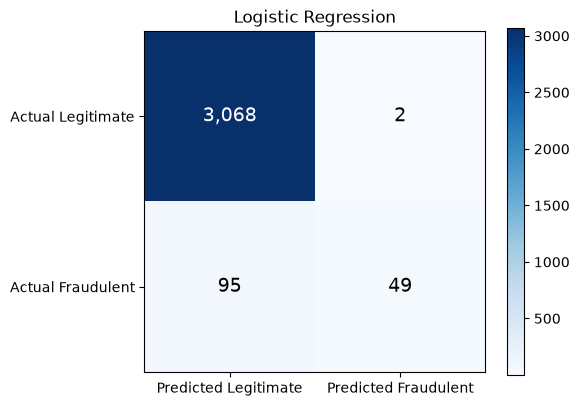

In [18]:
plot_confusion_matrix(y_test, logistic_pred, "Logistic Regression",
                      FIGURES_DIR / "logistic_confusion_matrix.png")

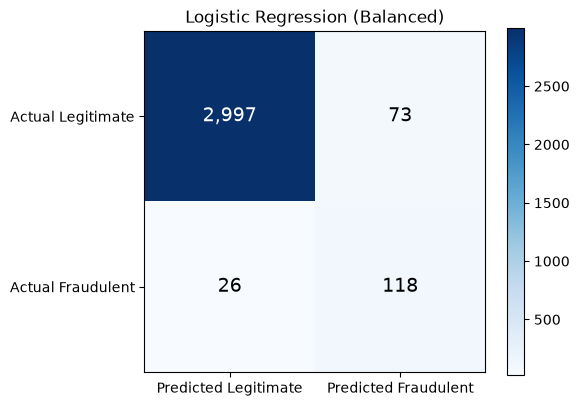

In [19]:
plot_confusion_matrix(y_test, balanced_pred, "Logistic Regression (Balanced)",
                      FIGURES_DIR / "logistic_balanced_confusion_matrix.png")

## 10. Comparison chart

Grouped bars for fraud precision, recall and F1, generated from the `results` table.

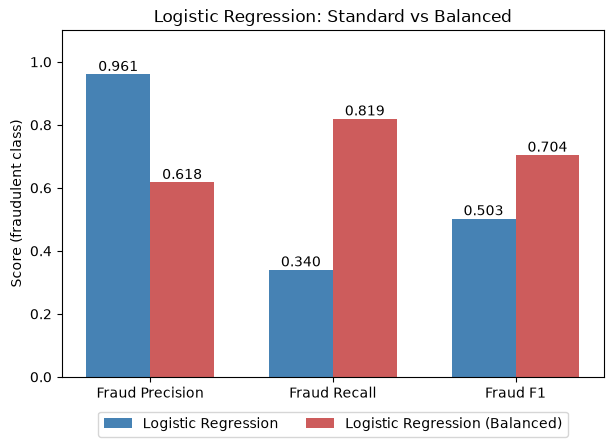

In [20]:
chart_metrics = ["Fraud Precision", "Fraud Recall", "Fraud F1"]
positions = np.arange(len(chart_metrics))
bar_width = 0.35

fig, ax = plt.subplots(figsize=(7, 4.5))
bars_standard = ax.bar(positions - bar_width / 2, results.loc[0, chart_metrics].astype(float),
                       bar_width, label=results.loc[0, "Model"], color="steelblue")
bars_balanced = ax.bar(positions + bar_width / 2, results.loc[1, chart_metrics].astype(float),
                       bar_width, label=results.loc[1, "Model"], color="indianred")
ax.bar_label(bars_standard, fmt="%.3f")
ax.bar_label(bars_balanced, fmt="%.3f")

ax.set_xticks(positions, labels=chart_metrics)
ax.set_ylim(0, 1.1)
ax.set_ylabel("Score (fraudulent class)")
ax.set_title("Logistic Regression: Standard vs Balanced")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2)
fig.savefig(FIGURES_DIR / "logistic_model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## 11. Save the metrics

The CSV holds the comparison table plus the confusion-matrix counts, so later milestones can add their rows to the same kind of table.

In [21]:
results.to_csv(METRICS_DIR / "logistic_regression_results.csv", index=False)
pd.read_csv(METRICS_DIR / "logistic_regression_results.csv")

,Model,Accuracy,Fraud Precision,Fraud Recall,Fraud F1,True Negatives,False Positives,False Negatives,True Positives
0,Logistic Regression,0.969820,0.960784,0.340278,0.502564,3068,2,95,49
1,Logistic Regression (Balanced),0.969197,0.617801,0.819444,0.704478,2997,73,26,118


## 12. Save the selected model as one pipeline

A scikit-learn **Pipeline** chains the steps: raw text goes in, TF-IDF converts it, Logistic Regression predicts. Saving **one** object means a future app can pass in raw `combined_text` and call `predict` without remembering to apply TF-IDF separately.

We build a **fresh** pipeline with the selected version's settings and train it on the **training text only**. The test data is not used for fitting.

In [22]:
selected_class_weight = "balanced" if selected_is_balanced else None

pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(**tfidf_settings)),
    ("logistic_regression", LogisticRegression(max_iter=1000, random_state=42,
                                               class_weight=selected_class_weight)),
])
pipeline.fit(X_train, y_train)   # raw training text in -> trained pipeline out

selected_pred_in_memory = pipeline.predict(X_test)
selected_reference_pred = balanced_pred if selected_is_balanced else logistic_pred
print("Selected version:", selected_name)
print("Pipeline predictions match the separately trained model:",
      bool((selected_pred_in_memory == selected_reference_pred).all()))

Selected version: Logistic Regression (Balanced)
Pipeline predictions match the separately trained model: True


In [23]:
PIPELINE_PATH = MODELS_DIR / "logistic_regression_pipeline.joblib"
joblib.dump(pipeline, PIPELINE_PATH)
print("Saved:", PIPELINE_PATH, f"({PIPELINE_PATH.stat().st_size / 1_000_000:.1f} MB)")

# Reload from disk and make sure it still works
reloaded_pipeline = joblib.load(PIPELINE_PATH)
reloaded_pred = reloaded_pipeline.predict(X_test)
print("Reloaded pipeline gives identical test predictions:", bool((reloaded_pred == selected_pred_in_memory).all()))
print("Example predictions on 5 test postings:", reloaded_pred[:5].tolist(), "| true labels:", y_test[:5].tolist())

Saved: ../models/logistic_regression_pipeline.joblib (1.0 MB)


Reloaded pipeline gives identical test predictions: True
Example predictions on 5 test postings: [0, 0, 0, 0, 0] | true labels: [0, 0, 0, 0, 0]


## 13. Sanity-check with demonstration examples

> **These examples are written by hand. They are NOT part of the test set and tell us nothing about the model's accuracy.** They only show that the saved pipeline accepts raw posting text and returns a prediction and a fraud probability.

We put each example through the same `create_combined_text` function used for the training data, so the text format is identical.

In [24]:
demo_examples = pd.DataFrame([
    {
        "name": "Professional posting (demo)",
        "title": "Software Engineer",
        "company_profile": "Northwind Analytics is a data company serving hospitals and universities. "
                           "We build tools that help researchers understand their data.",
        "description": "We are looking for a software engineer to join our platform team. You will design, "
                       "build and test backend services in Python, review code with teammates, and "
                       "participate in on-call rotation.",
        "requirements": "Bachelor's degree in computer science or equivalent experience. 3 years of Python "
                        "and SQL. Experience with automated testing and version control.",
        "benefits": "Health, dental and vision insurance, 401(k) match, paid vacation.",
    },
    {
        "name": "Suspicious posting (demo)",
        "title": "Work From Home - Earn $5000 Weekly!!!",
        "company_profile": "",
        "description": "No experience needed! Earn thousands every week from home. Limited spots. "
                       "Send your full name, address, date of birth and bank account details to "
                       "start immediately. A small registration fee is required.",
        "requirements": "Must have a bank account and be able to pay the registration fee.",
        "benefits": "",
    },
    {
        "name": "Very short posting (demo)",
        "title": "Data Entry Clerk",
        "company_profile": "",
        "description": "Data entry. Work from home. Apply now.",
        "requirements": "",
        "benefits": "",
    },
])

demo_text = create_combined_text(demo_examples)
demo_pred = reloaded_pipeline.predict(demo_text)
demo_prob = reloaded_pipeline.predict_proba(demo_text)[:, 1]

for name, prediction, probability in zip(demo_examples["name"], demo_pred, demo_prob):
    label = "Potentially Fraudulent" if prediction == 1 else "Likely Legitimate"
    print(f"{name:32s} -> {label:24s} (fraud probability: {probability:.3f})")

Professional posting (demo)      -> Likely Legitimate        (fraud probability: 0.105)
Suspicious posting (demo)        -> Potentially Fraudulent   (fraud probability: 0.799)
Very short posting (demo)        -> Potentially Fraudulent   (fraud probability: 0.995)


These are only three hand-written texts, so we should not read much into the results. They are a smoke test that the saved model loads, accepts raw text, and gives a probability.

## 14. What did the model learn? (top terms)

Logistic Regression assigns each term a **coefficient**. A **positive** coefficient pushes a posting toward "fraudulent"; a **negative** one pushes it toward "legitimate". We read them from the saved pipeline using its vocabulary.

**Important:** these are patterns the model found in the training data. They are **not proof that a word causes fraud**. Terms can be strong simply because of how the dataset was collected.

In [25]:
fitted_tfidf = reloaded_pipeline.named_steps["tfidf"]
fitted_model = reloaded_pipeline.named_steps["logistic_regression"]

term_names = fitted_tfidf.get_feature_names_out()
coefficients = fitted_model.coef_[0]
order = np.argsort(coefficients)                  # smallest (legitimate) -> largest (fraud)

top_fraud_terms = pd.Series(coefficients[order[-15:]][::-1], index=term_names[order[-15:]][::-1])
top_legit_terms = pd.Series(coefficients[order[:15]], index=term_names[order[:15]])

print("Terms with the strongest weights toward FRAUDULENT:")
print(top_fraud_terms.round(2).to_string())
print()
print("Terms with the strongest weights toward LEGITIMATE:")
print(top_legit_terms.round(2).to_string())

Terms with the strongest weights toward FRAUDULENT:
profile description    8.96
using link             3.96
accion                 3.96
apply using            3.63
earn                   3.42
link                   3.24
novation               3.21
data entry             3.19
engineering            3.14
assistant              3.10
line requirements      2.94
cash                   2.89
offshore               2.85
description apply      2.73
subsea                 2.69

Terms with the strongest weights toward LEGITIMATE:
team          -2.83
web           -2.53
companies     -2.47
digital       -2.29
english       -2.28
marketing     -2.21
growing       -2.12
clients       -2.08
based         -2.02
right         -1.92
client        -1.71
fun           -1.64
new           -1.64
creative      -1.64
recruitment   -1.63


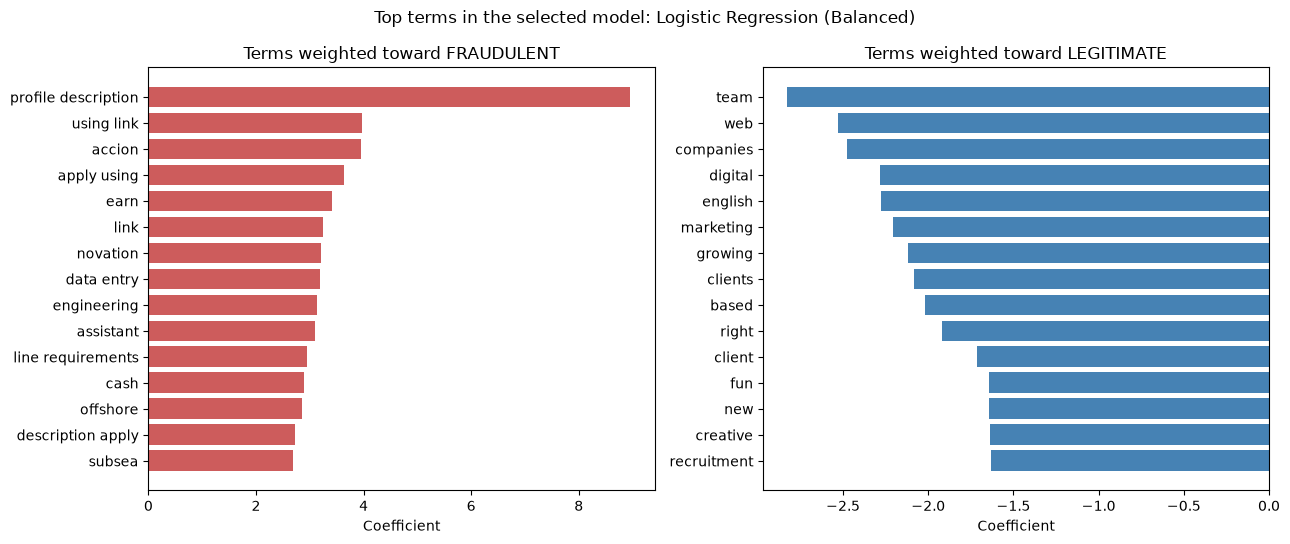

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

axes[0].barh(top_fraud_terms.index[::-1], top_fraud_terms.values[::-1], color="indianred")
axes[0].set_title("Terms weighted toward FRAUDULENT")
axes[0].set_xlabel("Coefficient")

axes[1].barh(top_legit_terms.index[::-1], top_legit_terms.values[::-1], color="steelblue")
axes[1].set_title("Terms weighted toward LEGITIMATE")
axes[1].set_xlabel("Coefficient")

fig.suptitle(f"Top terms in the selected model: {selected_name}")
plt.tight_layout()
fig.savefig(FIGURES_DIR / "logistic_top_terms.png", dpi=150, bbox_inches="tight")
plt.show()

How common are these terms? A strong weight on a term that appears in only a handful of training postings is less trustworthy than one that appears in many. The table counts, **in the training data**, how many postings contain each term and what share of those postings are fraudulent.

In [27]:
# Which training postings contain each term? (TF-IDF value > 0 means the term is present)
term_present = X_train_tfidf > 0
fraud_rows = (y_train.values == 1)
term_index = {term: position for position, term in enumerate(vocabulary)}

def term_summary(terms):
    rows = []
    for term in terms:
        column = term_present[:, term_index[term]]
        postings_with_term = int(column.sum())
        fraud_with_term = int(column[fraud_rows].sum())
        rows.append({"term": term,
                     "coefficient": round(float(coefficients[term_index[term]]), 2),
                     "training_postings_with_term": postings_with_term,
                     "percent_fraudulent": round(fraud_with_term / postings_with_term * 100, 1)})
    return pd.DataFrame(rows).set_index("term")

print("Fraud-associated terms:")
print(term_summary(top_fraud_terms.index).to_string())
print()
print("Legitimate-associated terms:")
print(term_summary(top_legit_terms.index).to_string())

Fraud-associated terms:
                     coefficient  training_postings_with_term  percent_fraudulent
term                                                                             
profile description         8.96                         2465                14.8
using link                  3.96                           35               100.0
accion                      3.96                           13               100.0
apply using                 3.63                           37                86.5
earn                        3.42                          279                29.4
link                        3.24                          316                16.1
novation                    3.21                           12               100.0
data entry                  3.19                          235                29.8
engineering                 3.14                         2305                 5.6
assistant                   3.10                          655             

In [28]:
# The section labels in combined_text can create terms too. When company_profile is empty,
# "COMPANY PROFILE:" and "DESCRIPTION:" end up side by side in the text.
empty_profile = train["combined_text"].str.contains("COMPANY PROFILE: \nDESCRIPTION:", regex=False)
print(f"Training postings with an empty company profile: {empty_profile.sum():,}")
print(f"  fraud rate when the profile is empty:     {train.loc[empty_profile, 'fraudulent'].mean() * 100:.1f}%")
print(f"  fraud rate when the profile is present:   {train.loc[~empty_profile, 'fraudulent'].mean() * 100:.1f}%")

Training postings with an empty company profile: 2,463
  fraud rate when the profile is empty:     14.8%
  fraud rate when the profile is present:   2.0%


### Reading these terms carefully

These weights come from the training data, so they describe what **this dataset** looks like, not necessarily real-world scam language.

- **The strongest fraud-associated term is a formatting effect.** `profile description` appears when the company profile is **empty**, because our `COMPANY PROFILE:` and `DESCRIPTION:` labels then sit side by side. The cell above shows that postings without a company profile are fraudulent much more often than postings with one, matching what we saw during data exploration. The model is partly using "missing company profile" as a clue.
- **Several fraud terms are rare.** Terms like `using link`, `accion`, `novation` and `subsea` appear in only a small number of training postings, almost all fraudulent. They probably come from a few groups of similar postings in the dataset (for example repeated "apply using the link" ads). They may not generalize to new scams.
- **Some fraud-weighted terms are common but only mildly associated** (check the `percent_fraudulent` column). A positive weight does not mean most postings with that word are fraudulent.
- **Legitimate-associated terms** are everyday business words (such as `team`, `clients`, `marketing`) found in thousands of postings that are rarely fraudulent.

We only say the model gave these terms relatively strong weights. We do **not** claim the words cause fraud.

## 15. Validation checks

Each `assert` stops the notebook with an error if the check fails.

In [29]:
# 1. TF-IDF vocabulary comes from the training text only:
#    refitting on X_train alone reproduces exactly the same vocabulary
refit_on_train_only = TfidfVectorizer(**tfidf_settings).fit(X_train)
assert list(refit_on_train_only.get_feature_names_out()) == list(vocabulary)
print("PASS: TF-IDF vocabulary equals the vocabulary learned from the training text alone")

# 2. The test matrix was only transformed: same columns as the training matrix, one row per test posting
assert X_test_tfidf.shape == (len(X_test), X_train_tfidf.shape[1])
assert X_train_tfidf.shape[0] == len(X_train)
print("PASS: test data was transformed with the training vocabulary (same columns, test row count)")

# 3. Both models were fitted on training-sized data with the training feature count
assert logistic.n_features_in_ == logistic_balanced.n_features_in_ == X_train_tfidf.shape[1]
assert len(y_train) == X_train_tfidf.shape[0]
print("PASS: models were fitted on the training matrix and training labels")

# 4. No overlap between train and test text
assert len(set(X_train) & set(X_test)) == 0
print("PASS: 0 identical combined_text values shared by train and test")

# 5. Metrics come from test predictions only
assert len(logistic_pred) == len(balanced_pred) == len(y_test)
assert sum(logistic_metrics[k] for k in ["True Negatives", "False Positives", "False Negatives", "True Positives"]) == len(y_test)
assert sum(balanced_metrics[k] for k in ["True Negatives", "False Positives", "False Negatives", "True Positives"]) == len(y_test)
print("PASS: confusion-matrix counts add up to the number of test postings")

# 6. Saved pipeline reloads and predicts
assert PIPELINE_PATH.exists()
assert (reloaded_pipeline.predict(X_test) == selected_pred_in_memory).all()
print("PASS: saved pipeline reloads and reproduces its predictions")

# 7. Saved metrics file matches the notebook's results
saved_results = pd.read_csv(METRICS_DIR / "logistic_regression_results.csv")
assert saved_results["Model"].tolist() == results["Model"].tolist()
assert np.allclose(saved_results[comparison_columns[1:]].values, results[comparison_columns[1:]].astype(float).values)
print("PASS: logistic_regression_results.csv matches the results table")

# 8. Figure files exist and are non-empty
for figure_name in ["logistic_confusion_matrix.png", "logistic_balanced_confusion_matrix.png",
                    "logistic_model_comparison.png", "logistic_top_terms.png"]:
    assert (FIGURES_DIR / figure_name).stat().st_size > 0
print("PASS: all four figure files were saved")

PASS: TF-IDF vocabulary equals the vocabulary learned from the training text alone
PASS: test data was transformed with the training vocabulary (same columns, test row count)
PASS: models were fitted on the training matrix and training labels
PASS: 0 identical combined_text values shared by train and test
PASS: confusion-matrix counts add up to the number of test postings


PASS: saved pipeline reloads and reproduces its predictions
PASS: logistic_regression_results.csv matches the results table
PASS: all four figure files were saved


## 16. Summary of Milestone 4

In [30]:
print("TF-IDF")
print(f"  Vocabulary size:       {len(vocabulary):,}")
print(f"  Training matrix shape: {X_train_tfidf.shape}")
print(f"  Testing matrix shape:  {X_test_tfidf.shape}")
print()
print(results[comparison_columns].round(4).to_string(index=False))
print()
print("Selected version:", selected_name)
print("Saved pipeline:  ", PIPELINE_PATH)

TF-IDF
  Vocabulary size:       20,000
  Training matrix shape: (12852, 20000)
  Testing matrix shape:  (3214, 20000)

                         Model  Accuracy  Fraud Precision  Fraud Recall  Fraud F1
           Logistic Regression    0.9698           0.9608        0.3403    0.5026
Logistic Regression (Balanced)    0.9692           0.6178        0.8194    0.7045

Selected version: Logistic Regression (Balanced)
Saved pipeline:   ../models/logistic_regression_pipeline.joblib


### What we learned
- **TF-IDF** turned each posting into a row of numbers that reflect which words and phrases are common or distinctive.
- **Logistic Regression** learned a weight for each term from the training postings and used them to estimate a fraud probability.
- **Class balancing** changes the trade-off between missed scams and false alarms; read the comparison above for how it changed *these* results.
- This is **one** model on **one** split. It is a baseline to compare against Naive Bayes, XGBoost and DistilBERT, not a finished product.

**Next milestone:** train **Multinomial Naive Bayes** on the same leakage-safe train/test data and compare its fraud-detection performance with Logistic Regression.